In [132]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

In [133]:
yield_df = pd.read_csv("../Dataset/crop_yield.csv")
price_df = pd.read_csv("../Dataset/agmarknet_india_historical_prices_2024_2025.csv")

In [134]:
yield_df.head()


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [135]:
price_df.head()

,Sl no.,District Name,Market Name,Commodity,Variety,Grade,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date,State
0,1,Auraiya,Achalda,Wheat,Dara,FAQ,2350.0,2550.0,2450.0,05 Apr 2025,Uttar Pradesh
1,2,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2500.0,2470.0,14 Jun 2025,Uttar Pradesh
2,3,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2500.0,2470.0,23 Jun 2025,Uttar Pradesh
3,4,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2520.0,2470.0,26 Jun 2025,Uttar Pradesh
4,5,Auraiya,Achalda,Wheat,Dara,FAQ,2400.0,2550.0,2500.0,03 Jun 2025,Uttar Pradesh


In [136]:
yield_df.info()
price_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   Region                  1000000 non-null  str    
 1   Soil_Type               1000000 non-null  str    
 2   Crop                    1000000 non-null  str    
 3   Rainfall_mm             1000000 non-null  float64
 4   Temperature_Celsius     1000000 non-null  float64
 5   Fertilizer_Used         1000000 non-null  bool   
 6   Irrigation_Used         1000000 non-null  bool   
 7   Weather_Condition       1000000 non-null  str    
 8   Days_to_Harvest         1000000 non-null  int64  
 9   Yield_tons_per_hectare  1000000 non-null  float64
dtypes: bool(2), float64(3), int64(1), str(4)
memory usage: 62.9 MB
<class 'pandas.DataFrame'>
RangeIndex: 1118899 entries, 0 to 1118898
Data columns (total 11 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------

In [137]:
price_df.dtypes

Sl no.                         int64
District Name                    str
Market Name                      str
Commodity                        str
Variety                          str
Grade                            str
Min Price (Rs./Quintal)      float64
Max Price (Rs./Quintal)      float64
Modal Price (Rs./Quintal)    float64
Price Date                       str
State                            str
dtype: object

In [138]:
yield_df.dtypes

Region                        str
Soil_Type                     str
Crop                          str
Rainfall_mm               float64
Temperature_Celsius       float64
Fertilizer_Used              bool
Irrigation_Used              bool
Weather_Condition             str
Days_to_Harvest             int64
Yield_tons_per_hectare    float64
dtype: object

In [139]:
price_df["Price Date"] = pd.to_datetime(
    price_df["Price Date"],
    format="%d %b %Y",
    errors="coerce"
)

In [140]:
price_df.dtypes

Sl no.                                int64
District Name                           str
Market Name                             str
Commodity                               str
Variety                                 str
Grade                                   str
Min Price (Rs./Quintal)             float64
Max Price (Rs./Quintal)             float64
Modal Price (Rs./Quintal)           float64
Price Date                   datetime64[us]
State                                   str
dtype: object

In [141]:
price_df.columns.tolist()

['Sl no.',
 'District Name',
 'Market Name',
 'Commodity',
 'Variety',
 'Grade',
 'Min Price (Rs./Quintal)',
 'Max Price (Rs./Quintal)',
 'Modal Price (Rs./Quintal)',
 'Price Date',
 'State']

In [142]:
yield_df.columns.tolist()

['Region',
 'Soil_Type',
 'Crop',
 'Rainfall_mm',
 'Temperature_Celsius',
 'Fertilizer_Used',
 'Irrigation_Used',
 'Weather_Condition',
 'Days_to_Harvest',
 'Yield_tons_per_hectare']

In [143]:
price_df.isnull().sum()

Sl no.                       0
District Name                0
Market Name                  0
Commodity                    0
Variety                      0
Grade                        0
Min Price (Rs./Quintal)      0
Max Price (Rs./Quintal)      0
Modal Price (Rs./Quintal)    0
Price Date                   0
State                        0
dtype: int64

In [144]:
yield_df.isnull().sum()

Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64

In [145]:
price_df.describe()

,Sl no.,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date
count,1.118899e+06,1.118899e+06,1.118899e+06,1.118899e+06,1118899
mean,9.949148e+03,3.978400e+03,4.643819e+03,4.364553e+03,2025-02-17 01:27:17.440019
min,1.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,2024-08-15 00:00:00
25%,2.597000e+03,2.000000e+03,2.355000e+03,2.225000e+03,2024-11-22 00:00:00
50%,6.849000e+03,3.000000e+03,3.800000e+03,3.500000e+03,2025-02-18 00:00:00
75%,1.445300e+04,5.125000e+03,6.000000e+03,5.675000e+03,2025-05-16 00:00:00
max,4.585900e+04,2.470000e+05,6.615110e+05,2.500000e+05,2025-08-14 00:00:00
std,9.637049e+03,4.341166e+03,4.854203e+03,4.534411e+03,NaN


In [146]:
yield_df.describe()

,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,549.981901,27.504965,104.495025,4.649472
std,259.851320,7.220608,25.953412,1.696572
min,100.000896,15.000034,60.000000,-1.147613
25%,324.891090,21.254502,82.000000,3.417637
50%,550.124061,27.507365,104.000000,4.651808
75%,774.738520,33.753267,127.000000,5.879200
max,999.998098,39.999997,149.000000,9.963372


In [147]:
price_df.duplicated().sum()

np.int64(0)

In [148]:
yield_df.duplicated().sum()

np.int64(0)

In [149]:
print("Negative Rainfall:", (yield_df["Rainfall_mm"] < 0).sum())

Negative Rainfall: 0


In [150]:

print("Non-positive Harvest Days:",
      (yield_df["Days_to_Harvest"] <= 0).sum())


Non-positive Harvest Days: 0


In [151]:

print("Negative Yield:",
      (yield_df["Yield_tons_per_hectare"] < 0).sum())


Negative Yield: 231


In [152]:

negative_yield = yield_df[
    yield_df["Yield_tons_per_hectare"] < 0
]

print("Negative yield rows:", len(negative_yield))

negative_yield.head(10)


Negative yield rows: 231


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
756,East,Peaty,Cotton,101.019421,33.804131,False,False,Rainy,117,-0.007103
7799,South,Chalky,Rice,108.804894,18.004082,False,False,Sunny,86,-0.061283
8421,East,Chalky,Soybean,168.120735,38.473430,False,False,Cloudy,111,-0.119911
9553,North,Silt,Wheat,156.607973,16.610257,False,False,Sunny,129,-0.193093
15435,South,Chalky,Maize,177.481344,27.719742,False,False,Sunny,94,-0.009811
19517,North,Clay,Maize,107.845638,21.855075,False,False,Rainy,118,-0.265207
22552,East,Sandy,Barley,136.608277,16.723985,False,False,Sunny,101,-0.235296
25967,West,Sandy,Wheat,143.407729,16.252040,False,False,Rainy,77,-0.023612
33285,West,Sandy,Rice,103.921766,16.314536,False,False,Cloudy,80,-0.060267
34902,East,Chalky,Soybean,144.431171,37.817570,False,False,Sunny,112,-0.028898


In [153]:

yield_df = yield_df[
    yield_df["Yield_tons_per_hectare"] >= 0
].copy()

print("Negative Yield:",
      (yield_df["Yield_tons_per_hectare"] < 0).sum())

print("Updated Dataset Shape:", yield_df.shape)


Negative Yield: 0
Updated Dataset Shape: (999769, 10)


In [154]:

print("Zero Yield:",
      (yield_df["Yield_tons_per_hectare"] == 0).sum())


Zero Yield: 0


In [155]:

print("Minimum Temperature:",
      yield_df["Temperature_Celsius"].min())

print("Maximum Temperature:",
      yield_df["Temperature_Celsius"].max())

print("Missing Temperatures:",
      yield_df["Temperature_Celsius"].isna().sum())

print("Below -10°C:",
      (yield_df["Temperature_Celsius"] < -10).sum())

print("Above 60°C:",
      (yield_df["Temperature_Celsius"] > 60).sum())


Minimum Temperature: 15.000034141430271
Maximum Temperature: 39.99999662316004
Missing Temperatures: 0
Below -10°C: 0
Above 60°C: 0


In [156]:

print("Regions:")
print(sorted(yield_df["Region"].dropna().unique()))

print("\nSoil Types:")
print(sorted(yield_df["Soil_Type"].dropna().unique()))

print("\nCrops:")
print(sorted(yield_df["Crop"].dropna().unique()))

print("\nWeather Conditions:")
print(sorted(yield_df["Weather_Condition"].dropna().unique()))


Regions:


['East', 'North', 'South', 'West']

Soil Types:
['Chalky', 'Clay', 'Loam', 'Peaty', 'Sandy', 'Silt']

Crops:
['Barley', 'Cotton', 'Maize', 'Rice', 'Soybean', 'Wheat']

Weather Conditions:
['Cloudy', 'Rainy', 'Sunny']


In [157]:
yield_df.to_csv("crop_yield_cleaned.csv", index=False)

print("Cleaned Crop Yield dataset saved!")
print("Shape:", yield_df.shape)

Cleaned Crop Yield dataset saved!
Shape: (999769, 10)


In [158]:
price_cols = [
    "Min Price (Rs./Quintal)",
    "Max Price (Rs./Quintal)",
    "Modal Price (Rs./Quintal)"
]

for col in price_cols:
    print(col, ":", (price_df[col] < 0).sum())

Min Price (Rs./Quintal) : 0
Max Price (Rs./Quintal) : 0
Modal Price (Rs./Quintal) : 0


In [159]:

min_col = "Min Price (Rs./Quintal)"
max_col = "Max Price (Rs./Quintal)"
modal_col = "Modal Price (Rs./Quintal)"

# Check 1: Min Price > Max Price
print("Min Price > Max Price:",
      (price_df[min_col] > price_df[max_col]).sum())

# Check 2: Modal Price range ke bahar
print("Modal Price Outside Range:",
      (
          (price_df[modal_col] < price_df[min_col]) |
          (price_df[modal_col] > price_df[max_col])
      ).sum())


Min Price > Max Price: 470
Modal Price Outside Range: 1200


In [160]:

invalid_prices = price_df[
    (price_df[min_col] > price_df[max_col]) |
    (price_df[modal_col] < price_df[min_col]) |
    (price_df[modal_col] > price_df[max_col])
]

print("Total Invalid Rows:", len(invalid_prices))

invalid_prices[
    [
        "District Name",
        "Market Name",
        "Commodity",
        min_col,
        max_col,
        modal_col,
        "Price Date",
        "State"
    ]
].head(20)


Total Invalid Rows: 1200


,District Name,Market Name,Commodity,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date,State
11009,Hamirpur,Raath,Wheat,2425.0,0.0,2440.0,2025-05-01,Uttar Pradesh
13640,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-04,Uttar Pradesh
14875,Gonda,Nawabganj,Wheat,0.0,0.0,2430.0,2025-04-08,Uttar Pradesh
18619,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-19,Uttar Pradesh
26215,Balrampur,Panchpedwa,Wheat,2425.0,0.0,2450.0,2025-05-22,Uttar Pradesh
27968,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2460.0,2025-04-22,Uttar Pradesh
30373,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-21,Uttar Pradesh
30600,Gonda,Nawabganj,Wheat,0.0,0.0,2440.0,2025-04-09,Uttar Pradesh
34111,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-16,Uttar Pradesh
34238,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-08,Uttar Pradesh


In [161]:

price_cols = [
    "Min Price (Rs./Quintal)",
    "Max Price (Rs./Quintal)",
    "Modal Price (Rs./Quintal)"
]

for col in price_cols:
    print(col, ":", (price_df[col] == 0).sum())


Min Price (Rs./Quintal) : 799
Max Price (Rs./Quintal) : 1200
Modal Price (Rs./Quintal) : 0


In [162]:

zero_price_rows = price_df[
    (price_df["Min Price (Rs./Quintal)"] == 0) |
    (price_df["Max Price (Rs./Quintal)"] == 0)
]

print("Total rows with zero Min/Max Price:", len(zero_price_rows))

zero_price_rows[
    [
        "District Name",
        "Market Name",
        "Commodity",
        "Min Price (Rs./Quintal)",
        "Max Price (Rs./Quintal)",
        "Modal Price (Rs./Quintal)",
        "Price Date",
        "State"
    ]
].head(10)


Total rows with zero Min/Max Price: 1269


,District Name,Market Name,Commodity,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date,State
11009,Hamirpur,Raath,Wheat,2425.0,0.0,2440.0,2025-05-01,Uttar Pradesh
13640,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-04,Uttar Pradesh
14875,Gonda,Nawabganj,Wheat,0.0,0.0,2430.0,2025-04-08,Uttar Pradesh
18619,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-19,Uttar Pradesh
26215,Balrampur,Panchpedwa,Wheat,2425.0,0.0,2450.0,2025-05-22,Uttar Pradesh
27968,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2460.0,2025-04-22,Uttar Pradesh
30373,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-21,Uttar Pradesh
30600,Gonda,Nawabganj,Wheat,0.0,0.0,2440.0,2025-04-09,Uttar Pradesh
34111,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-16,Uttar Pradesh
34238,Siddharth Nagar,Naugarh,Wheat,0.0,0.0,2425.0,2025-04-08,Uttar Pradesh


In [163]:

# Original cleaned dataset ka backup
mandi_backup = price_df.copy()

# Zero Min ya Max Price wali rows remove karo
mandi_clean = price_df[
    (price_df["Min Price (Rs./Quintal)"] > 0) &
    (price_df["Max Price (Rs./Quintal)"] > 0)
].copy()

print("Rows before removal:", len(mandi_backup))
print("Rows after removal:", len(mandi_clean))
print("Rows removed:", len(mandi_backup) - len(mandi_clean))

print("Zero Min Price:",
      (mandi_clean["Min Price (Rs./Quintal)"] == 0).sum())

print("Zero Max Price:",
      (mandi_clean["Max Price (Rs./Quintal)"] == 0).sum())


Rows before removal: 1118899
Rows after removal: 1117630
Rows removed: 1269
Zero Min Price: 0
Zero Max Price: 0


In [164]:

min_col = "Min Price (Rs./Quintal)"
max_col = "Max Price (Rs./Quintal)"
modal_col = "Modal Price (Rs./Quintal)"

print("Min Price > Max Price:",
      (mandi_clean[min_col] > mandi_clean[max_col]).sum())

print("Modal Price Outside Range:",
      (
          (mandi_clean[modal_col] < mandi_clean[min_col]) |
          (mandi_clean[modal_col] > mandi_clean[max_col])
      ).sum())


Min Price > Max Price: 0
Modal Price Outside Range: 0


In [165]:
mandi_clean.duplicated().sum()

np.int64(0)

In [166]:

price_cols = [
    "Min Price (Rs./Quintal)",
    "Max Price (Rs./Quintal)",
    "Modal Price (Rs./Quintal)"
]

for col in price_cols:
    print(col, ":", (mandi_clean[col] < 0).sum())


Min Price (Rs./Quintal) : 0
Max Price (Rs./Quintal) : 0
Modal Price (Rs./Quintal) : 0


In [167]:

mandi_clean[price_cols].describe()


,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal)
count,1.117630e+06,1.117630e+06,1.117630e+06
mean,3.980842e+03,4.648780e+03,4.360376e+03
std,4.341992e+03,4.854508e+03,4.528942e+03
min,1.000000e+00,2.200000e+01,2.000000e+01
25%,2.000000e+03,2.360000e+03,2.225000e+03
50%,3.000000e+03,3.800000e+03,3.500000e+03
75%,5.125000e+03,6.000000e+03,5.670000e+03
max,2.470000e+05,6.615110e+05,2.500000e+05


In [168]:

for col in price_cols:
    Q1 = mandi_clean[col].quantile(0.25)
    Q3 = mandi_clean[col].quantile(0.75)

    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (mandi_clean[col] < lower_limit) |
        (mandi_clean[col] > upper_limit)
    ).sum()

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers:", outliers)



Column: Min Price (Rs./Quintal)
Lower Limit: -2687.5
Upper Limit: 9812.5
Outliers: 46614

Column: Max Price (Rs./Quintal)
Lower Limit: -3100.0
Upper Limit: 11460.0
Outliers: 46305

Column: Modal Price (Rs./Quintal)
Lower Limit: -2942.5
Upper Limit: 10837.5
Outliers: 44229


In [169]:

mandi_clean.nlargest(10, "Modal Price (Rs./Quintal)")[
    [
        "District Name",
        "Market Name",
        "Commodity",
        "Variety",
        "Modal Price (Rs./Quintal)",
        "Price Date",
        "State"
    ]
]


,District Name,Market Name,Commodity,Variety,Modal Price (Rs./Quintal),Price Date,State
506296,Sanchore,Sanchore,Cauliflower,Cauliflower,250000.0,2024-11-11,Rajasthan
474704,Thiruvananthapuram,Pothencode,Garlic,Average,247040.0,2024-10-05,Kerala
474705,Thiruvananthapuram,Pothencode,Garlic,Average,247040.0,2024-10-09,Kerala
474702,Thiruvananthapuram,Pothencode,Garlic,Average,240540.0,2024-10-12,Kerala
474703,Thiruvananthapuram,Pothencode,Garlic,Average,240540.0,2024-10-16,Kerala
474668,Thiruvananthapuram,Pothencode,Garlic,Average,234040.0,2025-02-01,Kerala
474669,Thiruvananthapuram,Pothencode,Garlic,Average,234040.0,2024-11-02,Kerala
474670,Thiruvananthapuram,Pothencode,Garlic,Average,234040.0,2024-12-04,Kerala
474671,Thiruvananthapuram,Pothencode,Garlic,Average,234040.0,2025-01-04,Kerala
474672,Thiruvananthapuram,Pothencode,Garlic,Average,234040.0,2025-02-05,Kerala


In [170]:

mandi_clean.nlargest(
    10, "Modal Price (Rs./Quintal)"
)[
    [
        "Commodity",
        "Variety",
        "Grade",
        "Min Price (Rs./Quintal)",
        "Max Price (Rs./Quintal)",
        "Modal Price (Rs./Quintal)",
        "Price Date",
        "State"
    ]
].to_string(index=False)


'  Commodity     Variety Grade  Min Price (Rs./Quintal)  Max Price (Rs./Quintal)  Modal Price (Rs./Quintal) Price Date     State\nCauliflower Cauliflower   FAQ                 200000.0                 300000.0                   250000.0 2024-11-11 Rajasthan\n     Garlic     Average   FAQ                 247000.0                 247080.0                   247040.0 2024-10-05    Kerala\n     Garlic     Average   FAQ                 247000.0                 247080.0                   247040.0 2024-10-09    Kerala\n     Garlic     Average   FAQ                 240500.0                 240580.0                   240540.0 2024-10-12    Kerala\n     Garlic     Average   FAQ                 240500.0                 240580.0                   240540.0 2024-10-16    Kerala\n     Garlic     Average   FAQ                 234000.0                 234080.0                   234040.0 2025-02-01    Kerala\n     Garlic     Average   FAQ                 234000.0                 234080.0                 

In [171]:
# Check Garlic prices
garlic_data = mandi_clean[
    mandi_clean["Commodity"].str.strip().str.lower() == "garlic"
]

print("Garlic price summary:")
print(garlic_data[price_cols].describe())

# Check Cauliflower prices
cauliflower_data = mandi_clean[
    mandi_clean["Commodity"].str.strip().str.lower() == "cauliflower"
]

print("\nCauliflower price summary:")
print(cauliflower_data[price_cols].describe())

Garlic price summary:
       Min Price (Rs./Quintal)  Max Price (Rs./Quintal)  \
count             52523.000000             52523.000000   
mean              10859.404432             14378.584658   
std               13617.036554             14185.519290   
min                  46.000000               144.000000   
25%                5000.000000              6580.000000   
50%                7000.000000             11000.000000   
75%               15600.000000             19250.000000   
max              247000.000000            247080.000000   

       Modal Price (Rs./Quintal)  
count               52523.000000  
mean                12748.545532  
std                 13639.233867  
min                   144.000000  
25%                  6100.000000  
50%                  9200.000000  
75%                 18000.000000  
max                247040.000000  

Cauliflower price summary:
       Min Price (Rs./Quintal)  Max Price (Rs./Quintal)  \
count             69668.000000             6

In [172]:
# Save row count before removal
rows_before = len(mandi_clean)

# Remove high-price records for Garlic and Cauliflower
mask = (
    mandi_clean["Commodity"].str.strip().str.lower().isin(
        ["garlic", "cauliflower"]
    )
    & (mandi_clean["Modal Price (Rs./Quintal)"] > 50000)
)

mandi_clean = mandi_clean[~mask].copy()

# Check results
print("Rows before removal:", rows_before)
print("Rows removed:", rows_before - len(mandi_clean))
print("Rows after removal:", len(mandi_clean))

Rows before removal: 1117630
Rows removed: 212
Rows after removal: 1117418


In [173]:
# Save cleaned dataset
mandi_clean.to_csv(
    "mandi_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", mandi_clean.shape)

Cleaned dataset saved successfully!
Final dataset shape: (1117418, 11)



**EDA of yield dataset**


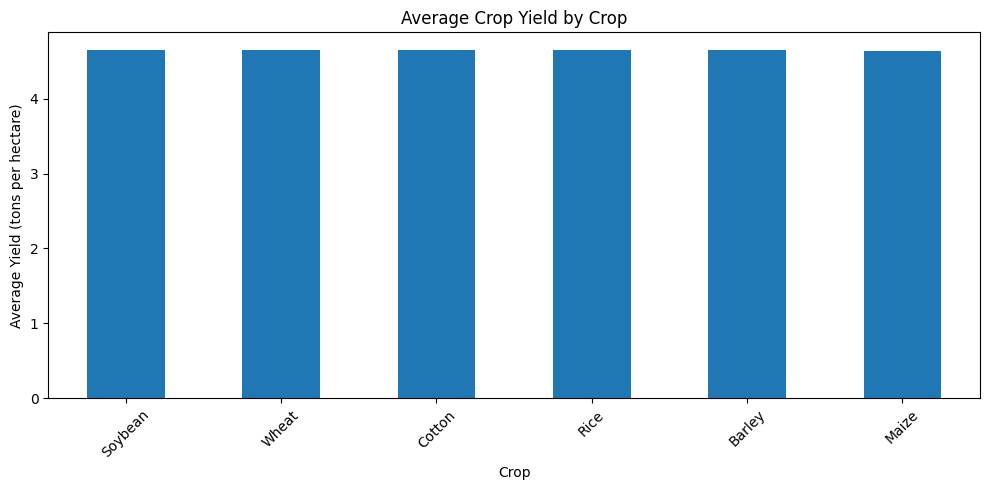

In [174]:

crop_avg_yield = (
    yield_df.groupby("Crop")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
crop_avg_yield.plot(kind="bar")

plt.title("Average Crop Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Average Yield (tons per hectare)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


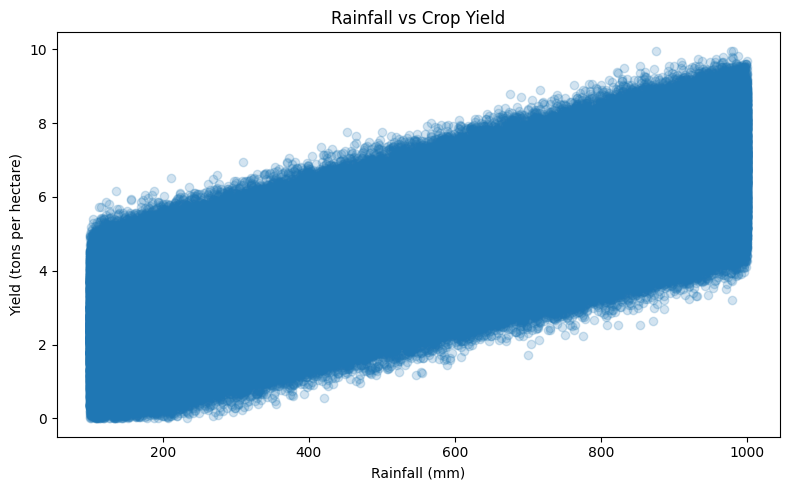

Rainfall-Yield Correlation: 0.765


In [175]:

plt.figure(figsize=(8, 5))

plt.scatter(
    yield_df["Rainfall_mm"],
    yield_df["Yield_tons_per_hectare"],
    alpha=0.2
)

plt.title("Rainfall vs Crop Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (tons per hectare)")
plt.tight_layout()
plt.show()

print(
    "Rainfall-Yield Correlation:",
    round(
        yield_df["Rainfall_mm"].corr(
            yield_df["Yield_tons_per_hectare"]
        ),
        3
    )
)


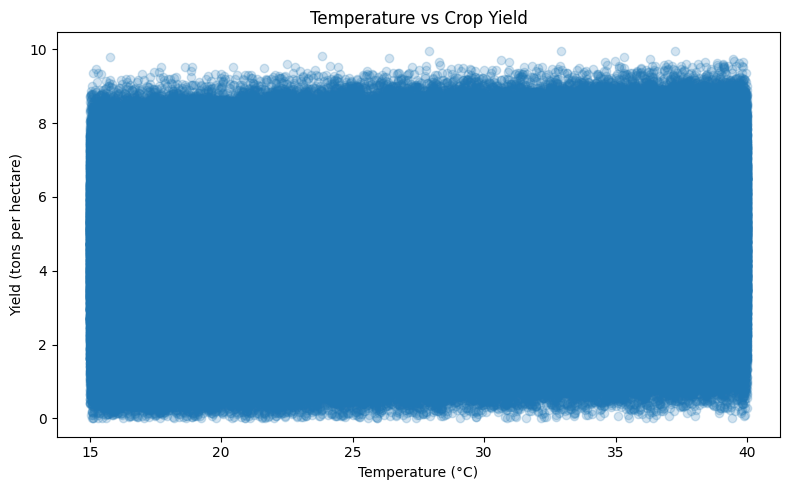

Temperature-Yield Correlation: 0.085


In [176]:

plt.figure(figsize=(8, 5))

plt.scatter(
    yield_df["Temperature_Celsius"],
    yield_df["Yield_tons_per_hectare"],
    alpha=0.2
)

plt.title("Temperature vs Crop Yield")
plt.xlabel("Temperature (°C)")
plt.ylabel("Yield (tons per hectare)")
plt.tight_layout()
plt.show()

correlation = yield_df["Temperature_Celsius"].corr(
    yield_df["Yield_tons_per_hectare"]
)

print("Temperature-Yield Correlation:", round(correlation, 3))


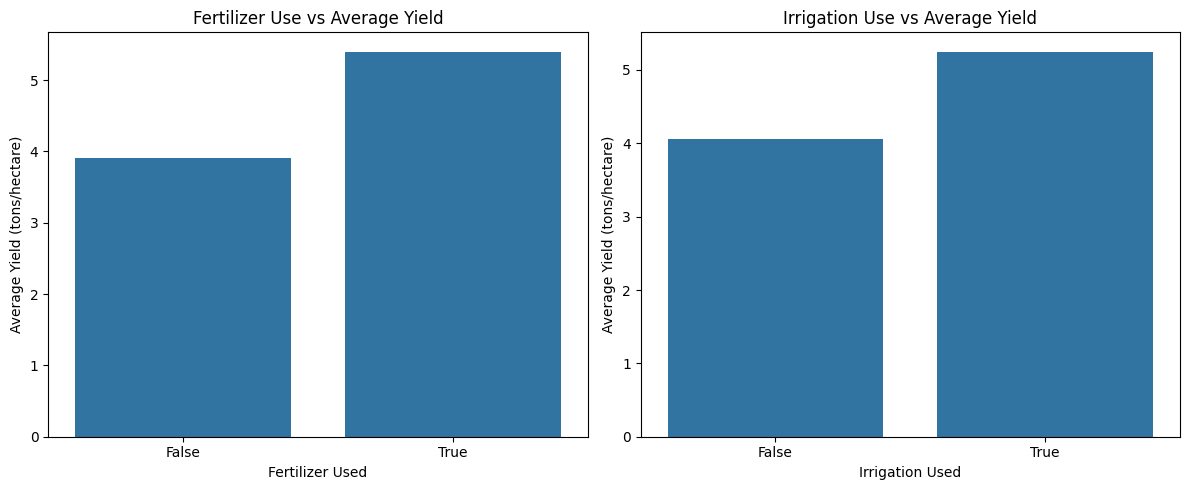

Yield by Fertilizer:


Fertilizer_Used
False    3.901
True     5.400
Name: Yield_tons_per_hectare, dtype: float64

Yield by Irrigation:


Irrigation_Used
False    4.052
True     5.250
Name: Yield_tons_per_hectare, dtype: float64

In [177]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=yield_df,
    x="Fertilizer_Used",
    y="Yield_tons_per_hectare",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Fertilizer Use vs Average Yield")
axes[0].set_xlabel("Fertilizer Used")
axes[0].set_ylabel("Average Yield (tons/hectare)")

sns.barplot(
    data=yield_df,
    x="Irrigation_Used",
    y="Yield_tons_per_hectare",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Irrigation Use vs Average Yield")
axes[1].set_xlabel("Irrigation Used")
axes[1].set_ylabel("Average Yield (tons/hectare)")

plt.tight_layout()
plt.show()

print("Yield by Fertilizer:")
display(yield_df.groupby("Fertilizer_Used")["Yield_tons_per_hectare"].mean().round(3))

print("Yield by Irrigation:")
display(yield_df.groupby("Irrigation_Used")["Yield_tons_per_hectare"].mean().round(3))


Average Yield by Soil Type:


Soil_Type
Chalky    4.654
Loam      4.652
Peaty     4.652
Sandy     4.650
Silt      4.650
Clay      4.646
Name: Yield_tons_per_hectare, dtype: float64

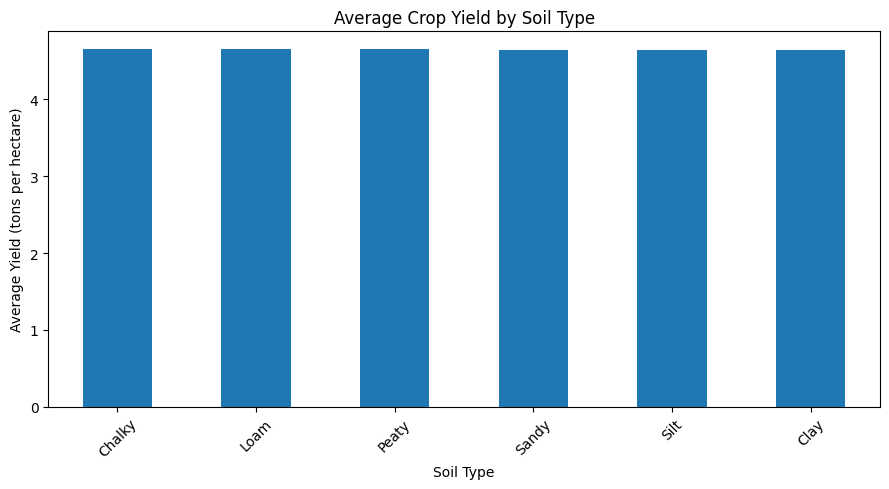

In [178]:

soil_yield = (
    yield_df.groupby("Soil_Type")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Yield by Soil Type:")
display(soil_yield.round(3))

plt.figure(figsize=(9, 5))
soil_yield.plot(kind="bar")

plt.title("Average Crop Yield by Soil Type")
plt.xlabel("Soil Type")
plt.ylabel("Average Yield (tons per hectare)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Average Yield by Weather Condition:


Weather_Condition
Sunny     4.653
Rainy     4.650
Cloudy    4.648
Name: Yield_tons_per_hectare, dtype: float64

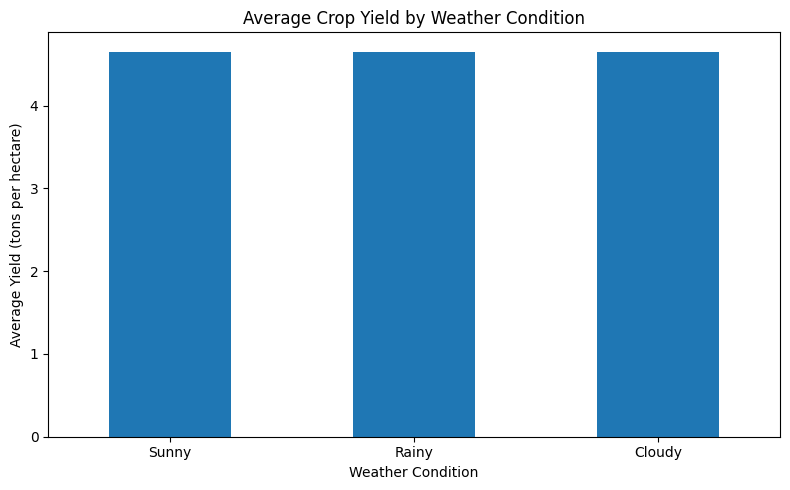

In [179]:

weather_yield = (
    yield_df.groupby("Weather_Condition")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Yield by Weather Condition:")
display(weather_yield.round(3))

plt.figure(figsize=(8, 5))
weather_yield.plot(kind="bar")

plt.title("Average Crop Yield by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Yield (tons per hectare)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


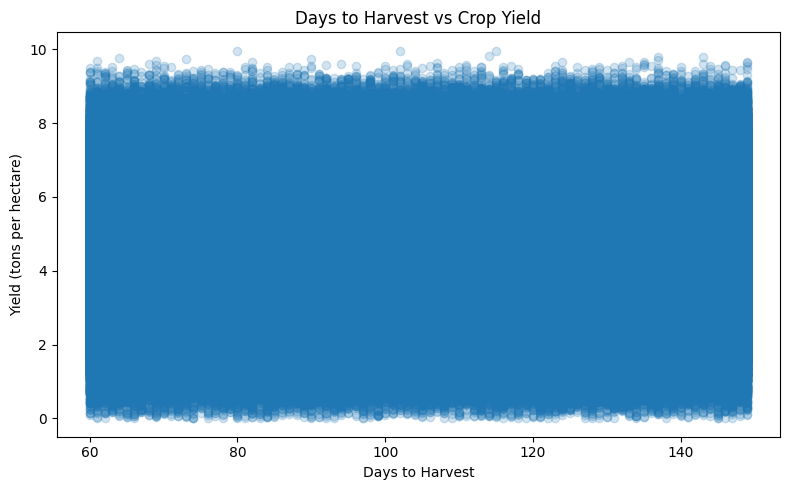

Days-to-Harvest vs Yield Correlation: -0.003


In [180]:

plt.figure(figsize=(8, 5))

plt.scatter(
    yield_df["Days_to_Harvest"],
    yield_df["Yield_tons_per_hectare"],
    alpha=0.2
)

plt.title("Days to Harvest vs Crop Yield")
plt.xlabel("Days to Harvest")
plt.ylabel("Yield (tons per hectare)")
plt.tight_layout()
plt.show()

correlation = yield_df["Days_to_Harvest"].corr(
    yield_df["Yield_tons_per_hectare"]
)

print("Days-to-Harvest vs Yield Correlation:", round(correlation, 3))


Average Yield by Region:


Region
North    4.655
West     4.650
South    4.650
East     4.647
Name: Yield_tons_per_hectare, dtype: float64

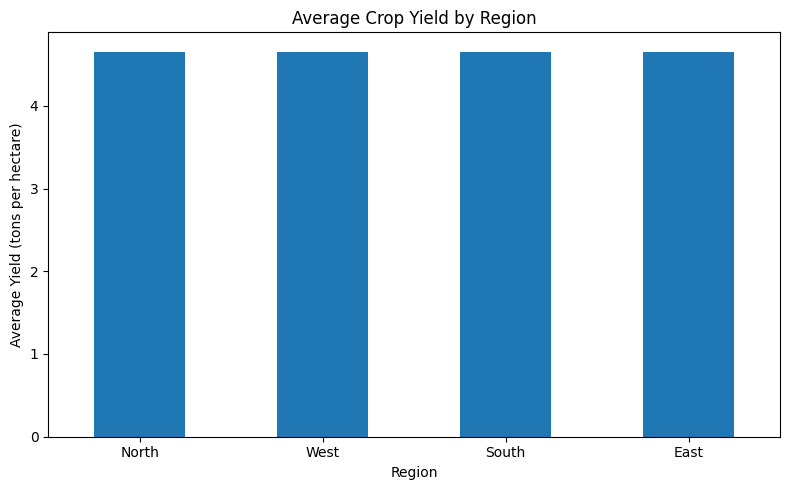

In [181]:

region_yield = (
    yield_df.groupby("Region")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Yield by Region:")
display(region_yield.round(3))

plt.figure(figsize=(8, 5))
region_yield.plot(kind="bar")

plt.title("Average Crop Yield by Region")
plt.xlabel("Region")
plt.ylabel("Average Yield (tons per hectare)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


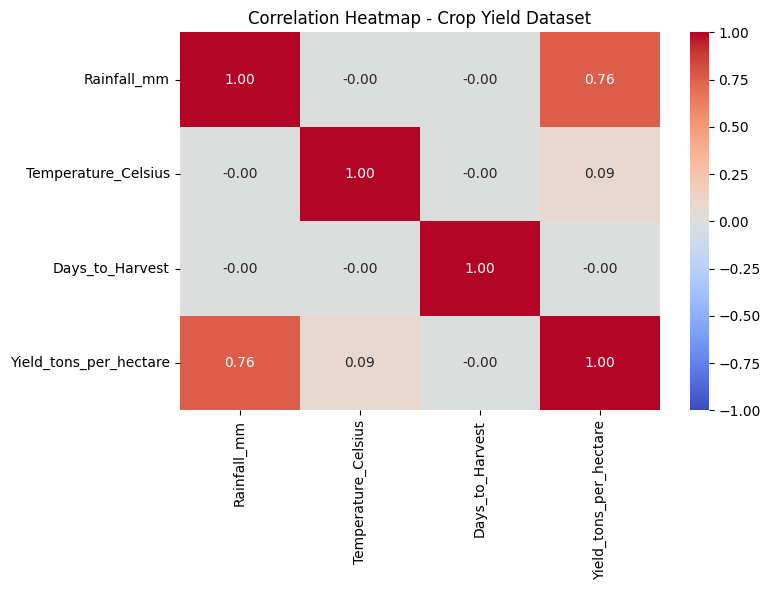

In [182]:

numeric_cols = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Days_to_Harvest",
    "Yield_tons_per_hectare"
]

correlation_matrix = yield_df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Crop Yield Dataset")
plt.tight_layout()
plt.show()


**EDA of Mandi dataset**

In [183]:
# Select Wheat records
wheat_df = mandi_clean[
    mandi_clean["Commodity"].str.strip().str.lower() == "wheat"
].copy()

In [184]:
# Convert date column
wheat_df["Price Date"] = pd.to_datetime(
    wheat_df["Price Date"], errors="coerce"
)

In [185]:
# Calculate monthly average modal price
wheat_df["Month"] = wheat_df["Price Date"].dt.to_period("M")

monthly_wheat = (
    wheat_df.groupby("Month")["Modal Price (Rs./Quintal)"]
    .mean()
)

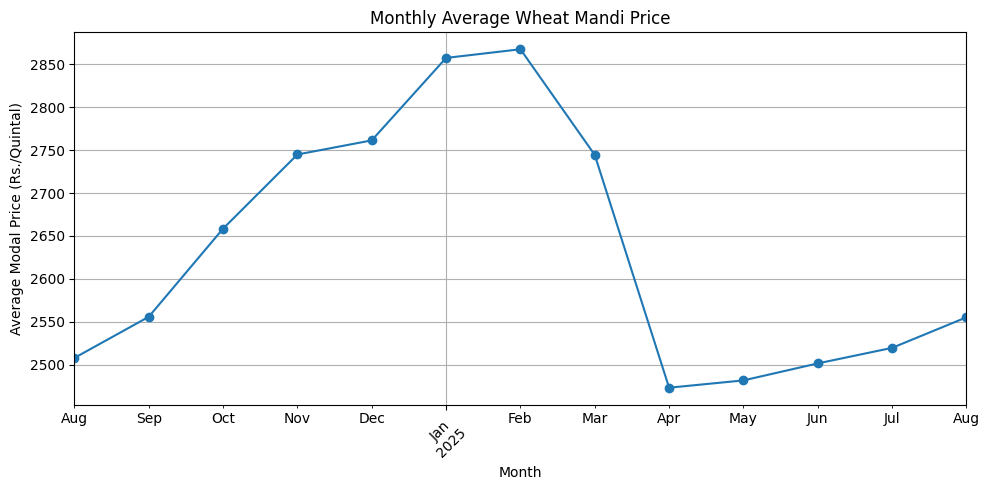

In [186]:
# Plot trend
monthly_wheat.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Average Wheat Mandi Price")
plt.xlabel("Month")
plt.ylabel("Average Modal Price (Rs./Quintal)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

Average Yield by Weather Condition:


Weather_Condition
Sunny     4.653
Rainy     4.650
Cloudy    4.648
Name: Yield_tons_per_hectare, dtype: float64

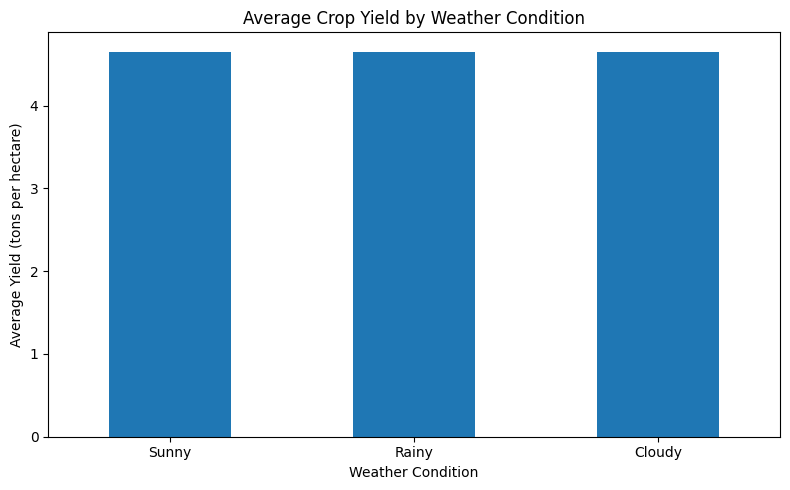

In [187]:

weather_yield = (
    yield_df.groupby("Weather_Condition")["Yield_tons_per_hectare"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Yield by Weather Condition:")
display(weather_yield.round(3))

plt.figure(figsize=(8, 5))
weather_yield.plot(kind="bar")

plt.title("Average Crop Yield by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Yield (tons per hectare)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [188]:
# Top 10 markets with highest average wheat price
market_prices = (
    wheat_df.groupby("Market Name")["Modal Price (Rs./Quintal)"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 markets with highest average Wheat price:")
print(market_prices.head(10))

# Bottom 10 markets with lowest average wheat price
print("\nTop 10 markets with lowest average Wheat price:")
print(market_prices.tail(10))

Top 10 markets with highest average Wheat price:
Market Name
Sojat Road                      3100.000000
Jodhpur (Grain)                 3000.000000
Udaipur (Grain)                 2962.027397
Karimpur                        2949.361371
Bilara                          2890.967742
Bishnupur(Bankura)              2883.818681
Khatra                          2882.802548
Rajdhanai Mandi (KukarKheda)    2850.000000
Bhagat Kii Phalodi              2850.000000
Nimbahera                       2845.194175
Name: Modal Price (Rs./Quintal), dtype: float64

Top 10 markets with lowest average Wheat price:
Market Name
Kandi          2412.317460
Shahabad       2405.098039
Anandnagar     2394.106464
Degana         2386.666667
Dhanaura       2376.111111
Bajju          2370.000000
Jahanabad      2352.758842
Dag            2345.296296
Maudaha        2341.315789
Kila Raipur    2320.000000
Name: Modal Price (Rs./Quintal), dtype: float64


In [189]:
state_analysis = wheat_df.groupby("State")["Modal Price (Rs./Quintal)"].mean()

print(state_analysis.sort_values(ascending=False).head(10))

State
West Bengal      2674.425676
Rajasthan        2645.419813
Uttar Pradesh    2616.151344
Punjab           2433.206861
Name: Modal Price (Rs./Quintal), dtype: float64


In [190]:
print(wheat_df["State"].nunique())
print(wheat_df["State"].unique())

4
<StringArray>
['Uttar Pradesh', 'West Bengal', 'Rajasthan', 'Punjab']
Length: 4, dtype: str


In [191]:
wheat_df["Month"] = wheat_df["Price Date"].dt.month

print(
    wheat_df.groupby("Month")["Modal Price (Rs./Quintal)"]
    .std()
)

Month
1     156.698253
2     168.205220
3     205.797478
4     124.250488
5     121.346132
6     123.271101
7     127.407675
8     116.214356
9     100.216091
10    114.624262
11    125.087402
12    129.385073
Name: Modal Price (Rs./Quintal), dtype: float64


In [192]:
print("Total Wheat records:", len(wheat_df))
print("Unique markets:", wheat_df["Market Name"].nunique())
print("Unique states:", wheat_df["State"].nunique())
print("Date range:", wheat_df["Price Date"].min(),
      "to", wheat_df["Price Date"].max())

Total Wheat records: 71283
Unique markets: 462
Unique states: 4
Date range: 2024-08-15 00:00:00 to 2025-08-14 00:00:00


In [193]:
print(wheat_df[
    ["Modal Price (Rs./Quintal)", "Price Date",
     "Market Name", "State"]
].isnull().sum())

Modal Price (Rs./Quintal)    0
Price Date                   0
Market Name                  0
State                        0
dtype: int64


In [194]:
daily_wheat = (
    wheat_df.groupby(["Market Name", "Price Date"])
    ["Modal Price (Rs./Quintal)"].mean()
    .reset_index()
)

daily_wheat = daily_wheat.sort_values(
    ["Market Name", "Price Date"]
)

daily_wheat["Price_Change"] = (
    daily_wheat.groupby("Market Name")
    ["Modal Price (Rs./Quintal)"].diff()
)

daily_wheat["Price_Direction"] = daily_wheat["Price_Change"].apply(
    lambda x: "Rise" if x > 0 else ("Fall" if x < 0 else "No Change")
)

print(daily_wheat.head(10))

  Market Name Price Date  Modal Price (Rs./Quintal)  Price_Change  \
0      Abohar 2025-04-07                     2601.0           NaN   
1      Abohar 2025-04-08                     2451.0        -150.0   
2      Abohar 2025-04-09                     2440.0         -11.0   
3      Abohar 2025-04-10                     2442.0           2.0   
4      Abohar 2025-04-11                     2430.0         -12.0   
5      Abohar 2025-04-12                     2430.0           0.0   
6      Abohar 2025-04-13                     2430.0           0.0   
7      Abohar 2025-04-14                     2430.0           0.0   
8      Abohar 2025-04-15                     2425.0          -5.0   
9      Abohar 2025-04-16                     2430.0           5.0   

  Price_Direction  
0       No Change  
1            Fall  
2            Fall  
3            Rise  
4            Fall  
5       No Change  
6       No Change  
7       No Change  
8            Fall  
9            Rise  


In [195]:
print(daily_wheat["Price_Direction"].value_counts())

Price_Direction
Rise         24534
Fall         21420
No Change    21058
Name: count, dtype: int64


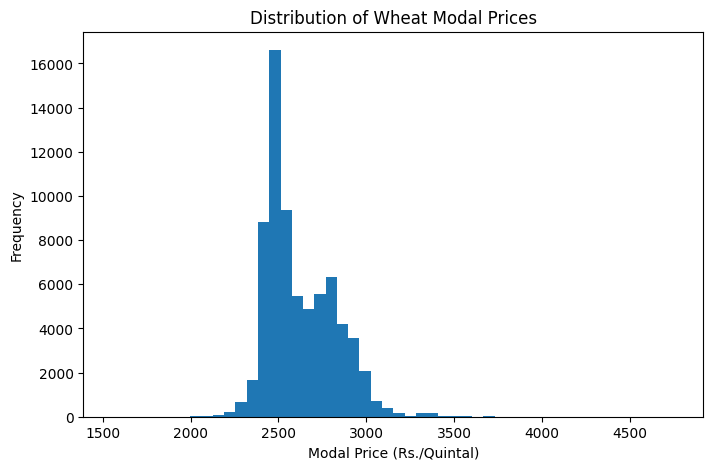

In [196]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    wheat_df["Modal Price (Rs./Quintal)"],
    bins=50
)

plt.title("Distribution of Wheat Modal Prices")
plt.xlabel("Modal Price (Rs./Quintal)")
plt.ylabel("Frequency")
plt.show()

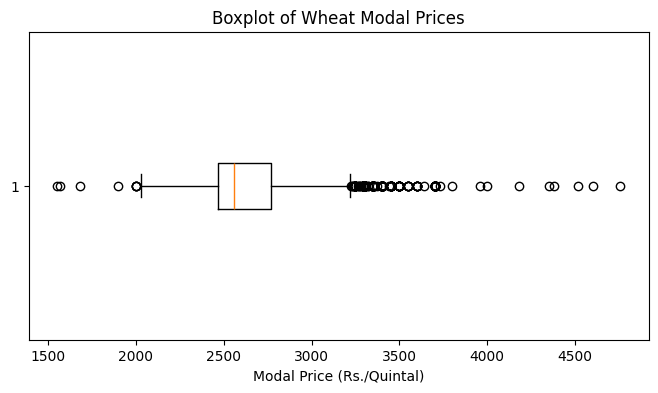

In [197]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.boxplot(
    wheat_df["Modal Price (Rs./Quintal)"].dropna(),
    vert=False
)

plt.title("Boxplot of Wheat Modal Prices")
plt.xlabel("Modal Price (Rs./Quintal)")
plt.show()

In [198]:
# Calculate Q1 and Q3
Q1 = wheat_df["Modal Price (Rs./Quintal)"].quantile(0.25)
Q3 = wheat_df["Modal Price (Rs./Quintal)"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = wheat_df[
    (wheat_df["Modal Price (Rs./Quintal)"] < lower_limit) |
    (wheat_df["Modal Price (Rs./Quintal)"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Potential Outliers:", len(outliers))

# Show some outlier records for investigation
print(outliers[
    ["Price Date", "State", "Market Name",
     "Variety", "Modal Price (Rs./Quintal)"]
].sort_values(
    "Modal Price (Rs./Quintal)", ascending=False
).head(10))

Q1: 2469.0
Q3: 2770.0
IQR: 301.0
Lower Limit: 2017.5
Upper Limit: 3221.5
Total Potential Outliers: 451
      Price Date          State      Market Name Variety  \
56818 2025-05-24      Rajasthan  Sri Vijayanagar   Other   
53878 2025-06-21      Rajasthan           Chaksu   Other   
4519  2024-10-27  Uttar Pradesh        Bachranwa    Dara   
53341 2025-04-14      Rajasthan     Jhalarapatan   Other   
15076 2024-11-04  Uttar Pradesh         Bharthna    Dara   
7434  2025-06-06  Uttar Pradesh        Balrampur    Dara   
61546 2025-05-31      Rajasthan           Chaksu   Other   
60862 2025-02-21      Rajasthan          Khandar   Other   
66405 2025-02-11      Rajasthan  Udaipur (Grain)   Farmi   
24375 2024-10-30  Uttar Pradesh          Jaunpur    Dara   

       Modal Price (Rs./Quintal)  
56818                     4758.0  
53878                     4600.0  
4519                      4515.0  
53341                     4382.0  
15076                     4350.0  
7434                      

In [199]:
# Outliers by state
print("Outliers by State:")
print(outliers["State"].value_counts())

# Outliers by market
print("\nTop 10 Markets with Most Outliers:")
print(outliers["Market Name"].value_counts().head(10))

# Outlier price statistics
print("\nOutlier Price Statistics:")
print(outliers["Modal Price (Rs./Quintal)"].describe())

Outliers by State:
State
Rajasthan        355
West Bengal       76
Uttar Pradesh     20
Name: count, dtype: int64

Top 10 Markets with Most Outliers:
Market Name
Udaipur (Grain)         304
Karimpur                 76
Beawar                   11
Fatehnagar                6
Baran                     5
Bilara                    3
Chaksu                    3
Itawa                     3
Madanganj Kishangarh      3
Nahargarh                 3
Name: count, dtype: int64

Outlier Price Statistics:
count     451.000000
mean     3373.172949
std       277.520027
min      1550.000000
25%      3300.000000
50%      3350.000000
75%      3400.000000
max      4758.000000
Name: Modal Price (Rs./Quintal), dtype: float64


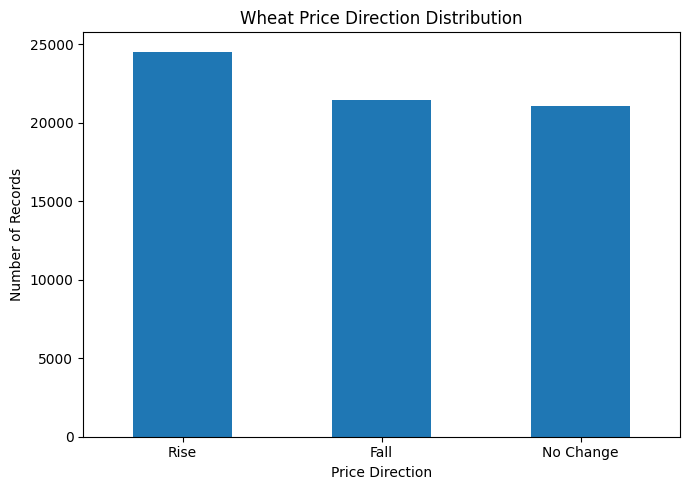

Price_Direction
Rise         24534
Fall         21420
No Change    21058
Name: count, dtype: int64


In [200]:
import matplotlib.pyplot as plt

direction_counts = daily_wheat["Price_Direction"].value_counts()

direction_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Wheat Price Direction Distribution")
plt.xlabel("Price Direction")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(direction_counts)

In [201]:
udaipur_outliers = outliers[
    outliers["Market Name"] == "Udaipur (Grain)"
]

print("Udaipur outlier count:", len(udaipur_outliers))

print(
    udaipur_outliers[
        ["Price Date", "State", "Market Name",
         "Commodity", "Variety", "Min Price (Rs./Quintal)",
         "Max Price (Rs./Quintal)",
         "Modal Price (Rs./Quintal)"]
    ].sort_values("Price Date").head(15).to_string(index=False)
)

Udaipur outlier count: 304
Price Date     State     Market Name Commodity Variety  Min Price (Rs./Quintal)  Max Price (Rs./Quintal)  Modal Price (Rs./Quintal)
2024-11-08 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3100.0                   3500.0                     3300.0
2024-11-09 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3100.0                   3500.0                     3300.0
2024-11-11 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3100.0                   3500.0                     3300.0
2024-11-12 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3100.0                   3500.0                     3300.0
2024-11-15 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3100.0                   3500.0                     3300.0
2024-11-16 Rajasthan Udaipur (Grain)     Wheat   Farmi                   3150.0                   3550.0                     3350.0
2024-11-18 Rajasthan Udaipur (Grain)     Wheat   

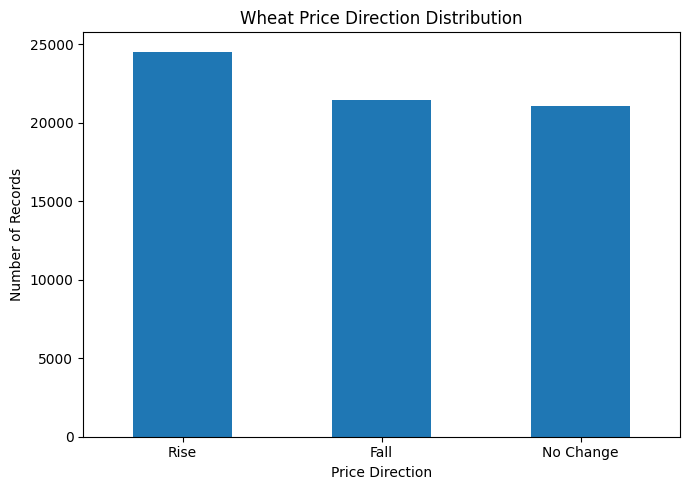

Price_Direction
Rise         24534
Fall         21420
No Change    21058
Name: count, dtype: int64


In [202]:
import matplotlib.pyplot as plt

direction_counts = daily_wheat["Price_Direction"].value_counts()

direction_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Wheat Price Direction Distribution")
plt.xlabel("Price Direction")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(direction_counts)

In [203]:
commodity_analysis = (
    mandi_clean.groupby("Commodity")
    .agg(
        Average_Price=("Modal Price (Rs./Quintal)", "mean"),
        Median_Price=("Modal Price (Rs./Quintal)", "median"),
        Total_Records=("Modal Price (Rs./Quintal)", "count")
    )
    .sort_values("Average_Price", ascending=False)
)

print("Top 10 Commodities by Average Modal Price:")
print(commodity_analysis.head(10).round(2))

Top 10 Commodities by Average Modal Price:
                             Average_Price  Median_Price  Total_Records
Commodity                                                              
Garlic                            12076.76        9060.0          52334
Apple                              9002.86        8255.0          54923
Green Gram (Moong)(Whole)          7304.61        7005.5          18924
Arhar (Tur/Red Gram)(Whole)        7286.40        6750.0          18586
Cotton                             7106.33        7125.0          22476
Lentil (Masur)(Whole)              6306.15        6115.0          29575
Mustard                            5865.18        5850.0          71357
Ginger(Green)                      5774.68        4540.0          55196
Groundnut                          5089.71        5001.0          22523
Mango                              4509.22        4000.0          15002


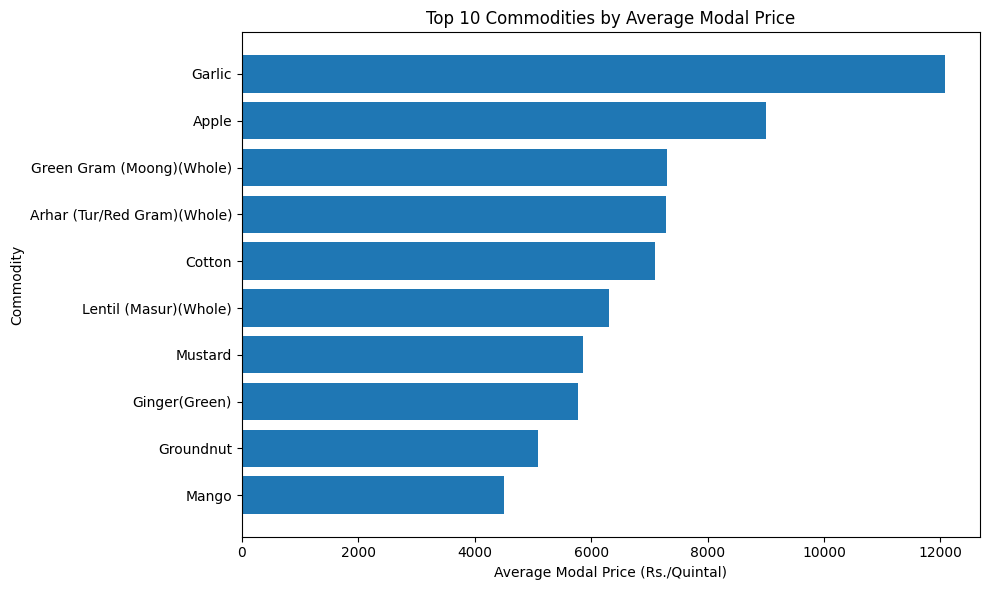

In [204]:
import matplotlib.pyplot as plt

top_10 = commodity_analysis.head(10).sort_values(
    "Average_Price"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10.index,
    top_10["Average_Price"]
)

plt.title("Top 10 Commodities by Average Modal Price")
plt.xlabel("Average Modal Price (Rs./Quintal)")
plt.ylabel("Commodity")
plt.tight_layout()
plt.show()

In [205]:
state_price_analysis = (
    mandi_clean.groupby("State")
    .agg(
        Average_Price=("Modal Price (Rs./Quintal)", "mean"),
        Median_Price=("Modal Price (Rs./Quintal)", "median"),
        Min_Price=("Modal Price (Rs./Quintal)", "min"),
        Max_Price=("Modal Price (Rs./Quintal)", "max"),
        Price_Std=("Modal Price (Rs./Quintal)", "std"),
        Total_Records=("Modal Price (Rs./Quintal)", "count")
    )
    .sort_values("Average_Price", ascending=False)
)

print(state_price_analysis.round(2))

                Average_Price  Median_Price  Min_Price  Max_Price  Price_Std  \
State                                                                          
Kerala                5986.90        4500.0       20.0   162540.0    5892.37   
Rajasthan             4413.97        3877.0      200.0    35000.0    2863.61   
Madhya Pradesh        4412.77        4165.0       32.0    41000.0    3004.35   
West Bengal           4370.80        3600.0      180.0    34500.0    3536.93   
Gujarat               4248.23        3825.0      150.0    35500.0    2744.07   
Uttar Pradesh         3942.99        2740.0      107.5    33000.0    3326.21   
Andhra Pradesh        3754.41        3500.0      300.0     9559.0    2031.97   
Punjab                3567.18        2500.0       80.0    36000.0    3758.35   

                Total_Records  
State                          
Kerala                 136799  
Rajasthan              106697  
Madhya Pradesh         174931  
West Bengal             61961  
Gujarat

In [206]:
market_records = (
    mandi_clean.groupby(["State", "Market Name"])
    .size()
    .reset_index(name="Total_Records")
    .sort_values("Total_Records", ascending=False)
)

print("Top 15 Markets by Record Count:")
print(market_records.head(15).to_string(index=False))

Top 15 Markets by Record Count:
        State   Market Name  Total_Records
Uttar Pradesh       Aligarh           4948
Uttar Pradesh     Lakhimpur           4399
Uttar Pradesh         Gonda           4354
Uttar Pradesh     Ghaziabad           4304
Uttar Pradesh    Saharanpur           4286
Uttar Pradesh Kanpur(Grain)           4223
Uttar Pradesh      Bahraich           4175
Uttar Pradesh    Pukharayan           4124
Uttar Pradesh       Mathura           3975
Uttar Pradesh     Nawabganj           3862
Uttar Pradesh         Unnao           3805
Uttar Pradesh        Shamli           3801
Uttar Pradesh      Mainpuri           3753
Uttar Pradesh          Etah           3687
Uttar Pradesh     Firozabad           3681


In [207]:
print("Start Date:", mandi_clean["Price Date"].min())
print("End Date:", mandi_clean["Price Date"].max())
print("Unique Dates:", mandi_clean["Price Date"].nunique())

duplicate_keys = mandi_clean.duplicated(
    subset=["State", "Market Name", "Commodity", "Price Date"]
)

print(
    "Repeated State-Market-Commodity-Date combinations:",
    duplicate_keys.sum()
)

daily_records = mandi_clean.groupby("Price Date").size()

print("\nRecords per date — summary:")
print(daily_records.describe().round(2))

Start Date: 2024-08-15 00:00:00
End Date: 2025-08-14 00:00:00
Unique Dates: 365
Repeated State-Market-Commodity-Date combinations: 52157

Records per date — summary:
count     365.00
mean     3061.42
std       871.90
min       782.00
25%      2807.00
50%      3370.00
75%      3671.00
max      4223.00
dtype: float64


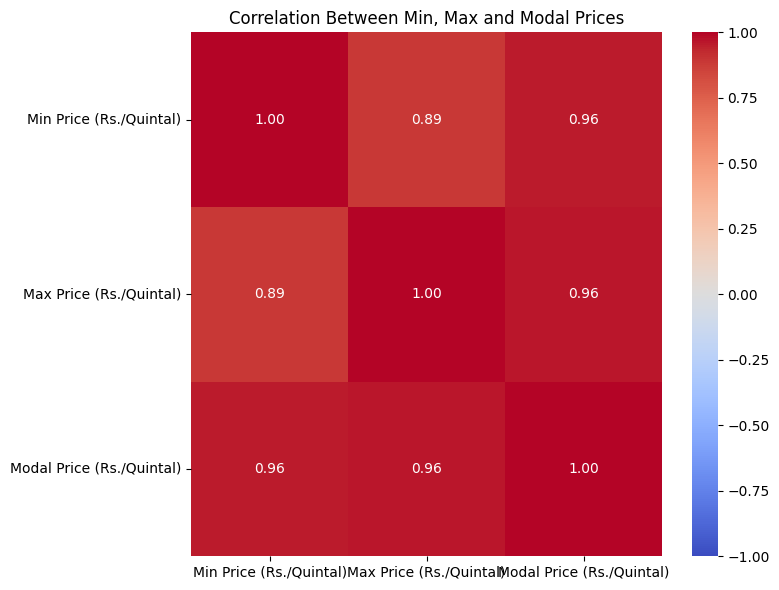

In [208]:
import matplotlib.pyplot as plt
import seaborn as sns

price_columns = [
    "Min Price (Rs./Quintal)",
    "Max Price (Rs./Quintal)",
    "Modal Price (Rs./Quintal)"
]

price_corr = mandi_clean[price_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    price_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Min, Max and Modal Prices")
plt.tight_layout()
plt.show()

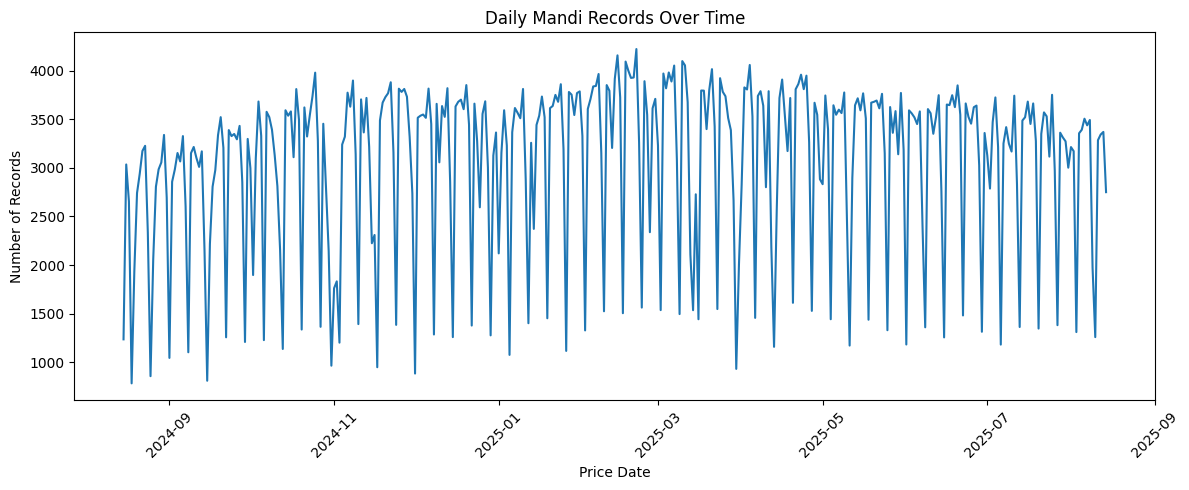

In [209]:
daily_records = mandi_clean.groupby("Price Date").size()

plt.figure(figsize=(12, 5))
plt.plot(daily_records.index, daily_records.values)

plt.title("Daily Mandi Records Over Time")
plt.xlabel("Price Date")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()